<a href="https://colab.research.google.com/github/Nhut214/vietnamese_student_feedback_sentiment_analysis/blob/main/notebooks/04_BiLSTM_UIT_VSFC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Đường dẫn dữ liệu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data
Train: (11426, 3)
Validation: (1583, 3)
Test: (3166, 3)

Phân bố nhãn tập train:
sentiment
Negative    5325
Neutral      458
Positive    5643
Name: count, dtype: int64


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0


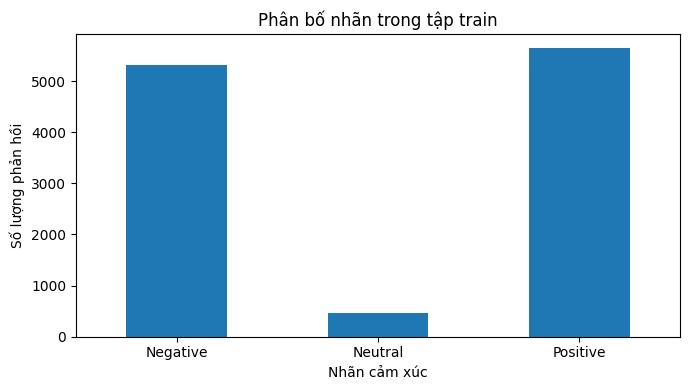

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

LABEL_IDS = [0, 1, 2]
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
ID2LABEL = {0: "Negative", 1: "Neutral", 2: "Positive"}
LABEL2ID = {"Negative": 0, "Neutral": 1, "Positive": 2}

DATA_DIR = r"/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data"

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
VALIDATION_PATH = os.path.join(DATA_DIR, "validation.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

for path in [TRAIN_PATH, VALIDATION_PATH, TEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy file: {path}\n"
            "Hãy kiểm tra lại tên thư mục và tên file trong Google Drive."
        )

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

def clean_dataframe(df, name):
    required_columns = {"sentence", "sentiment"}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Tập {name} thiếu các cột bắt buộc: {missing_columns}"
        )

    cleaned = df.dropna(subset=["sentence", "sentiment"]).copy()
    cleaned["sentence"] = cleaned["sentence"].astype(str).str.strip()
    cleaned["sentiment"] = pd.to_numeric(
        cleaned["sentiment"],
        errors="coerce"
    )
    cleaned = cleaned.dropna(subset=["sentiment"])
    cleaned["sentiment"] = cleaned["sentiment"].astype(int)
    cleaned = cleaned[
        cleaned["sentiment"].isin(LABEL_IDS)
    ]
    cleaned = cleaned[
        cleaned["sentence"].str.len() > 0
    ].reset_index(drop=True)

    return cleaned

train_df = clean_dataframe(train_df, "train")
val_df = clean_dataframe(val_df, "validation")
test_df = clean_dataframe(test_df, "test")

# Các biến nhãn được tạo ngay sau khi đọc dữ liệu.
y_train = train_df["sentiment"].to_numpy(dtype=np.int64)
y_val = val_df["sentiment"].to_numpy(dtype=np.int64)
y_test = test_df["sentiment"].to_numpy(dtype=np.int64)

print("Đường dẫn dữ liệu:", DATA_DIR)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nPhân bố nhãn tập train:")
print(
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

display(train_df.head())

train_counts = (
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

train_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Phân bố nhãn trong tập train")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng phản hồi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

RESULTS = []

def evaluate_predictions(
    model_name,
    experiment,
    y_true,
    y_pred,
    show_confusion_matrix=True
):
    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        )
    )

    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=LABEL_IDS,
        average="weighted",
        zero_division=0
    )

    class_precision, class_recall, class_f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average=None,
            zero_division=0
        )
    )

    result = {
        "Model": model_name,
        "Experiment": experiment,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Negative Precision": class_precision[0],
        "Negative Recall": class_recall[0],
        "Negative F1": class_f1[0],
        "Neutral Precision": class_precision[1],
        "Neutral Recall": class_recall[1],
        "Neutral F1": class_f1[1],
        "Positive Precision": class_precision[2],
        "Positive Recall": class_recall[2],
        "Positive F1": class_f1[2],
        "Neutral Support": int(support[1]),
    }

    RESULTS.append(result)

    print(f"\n{model_name} — {experiment}")
    print("=" * 72)
    print(
        classification_report(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            target_names=LABEL_NAMES,
            digits=4,
            zero_division=0
        )
    )

    if show_confusion_matrix:
        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=LABEL_IDS
        )
        display_matrix = ConfusionMatrixDisplay(
            matrix,
            display_labels=LABEL_NAMES
        )
        display_matrix.plot(values_format="d")
        plt.title(f"{model_name} — {experiment}")
        plt.tight_layout()
        plt.show()

    return result


def export_results(filename):
    if not RESULTS:
        raise ValueError("Chưa có kết quả để xuất.")

    result_df = (
        pd.DataFrame(RESULTS)
        .drop_duplicates(
            subset=["Model", "Experiment"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    metric_columns = [
        column
        for column in result_df.columns
        if column not in [
            "Model",
            "Experiment",
            "Neutral Support"
        ]
    ]

    display_df = result_df.copy()
    display_df[metric_columns] = (
        display_df[metric_columns].round(4)
    )

    display(display_df)

    output_path = os.path.join(
        "/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC",
        filename
    )
    result_df.to_csv(output_path, index=False)

    print("Đã lưu kết quả tại:", output_path)
    return result_df


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print(
    "GPU khả dụng:",
    tf.config.list_physical_devices("GPU")
)

MAX_TOKENS = 30000
SEQUENCE_LENGTH = 80
EMBEDDING_DIM = 128
RNN_UNITS = 128
BATCH_SIZE = 64
EPOCHS = 8

text_vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize=None
)

text_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        train_df["sentence"].astype(str).values
    ).batch(256)
)

VOCAB_SIZE = len(
    text_vectorizer.get_vocabulary()
)

class_values = np.array(LABEL_IDS)
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=y_train
)

CLASS_WEIGHT = {
    int(label): float(weight)
    for label, weight in zip(
        class_values,
        class_weight_values
    )
}

print("Kích thước từ vựng:", VOCAB_SIZE)
print("Trọng số lớp:", CLASS_WEIGHT)

def create_tf_dataset(df, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            df["sentence"].astype(str).values,
            df["sentiment"].to_numpy(
                dtype=np.int32
            )
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return (
        dataset
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

train_dataset = create_tf_dataset(
    train_df,
    shuffle=True
)
validation_dataset = create_tf_dataset(val_df)
test_dataset = create_tf_dataset(test_df)

print("Số mẫu train:", len(y_train))
print("Số mẫu validation:", len(y_val))
print("Số mẫu test:", len(y_test))


TensorFlow: 2.20.0
GPU khả dụng: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Kích thước từ vựng: 2516
Trọng số lớp: {0: 0.7152425665101722, 1: 8.315866084425036, 2: 0.674936499497903}
Số mẫu train: 11426
Số mẫu validation: 1583
Số mẫu test: 3166



## 1. Xây dựng mô hình BiLSTM

Kiến trúc:

`Text → TextVectorization → Embedding → Bidirectional LSTM → Dense → Softmax`


In [ ]:

def build_bilstm_model():
    text_input = keras.Input(
        shape=(),
        dtype=tf.string,
        name="sentence"
    )

    x = text_vectorizer(text_input)

    x = layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="embedding"
    )(x)

    x = layers.Bidirectional(
        layers.LSTM(RNN_UNITS),
        name="bidirectional_lstm"
    )(x)

    x = layers.Dropout(0.4)(x)
    x = layers.Dense(
        64,
        activation="relu"
    )(x)
    x = layers.Dropout(0.3)(x)

    output = layers.Dense(
        3,
        activation="softmax",
        name="sentiment"
    )(x)

    model = keras.Model(
        inputs=text_input,
        outputs=output
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [ ]:

def train_and_evaluate_rnn(
    model,
    model_name,
    experiment,
    class_weight=None
):
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=1e-5
        )
    ]

    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EPOCHS,
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = model.predict(
        test_dataset,
        verbose=0
    )
    predictions = probabilities.argmax(axis=1)

    evaluate_predictions(
        model_name,
        experiment,
        y_test,
        predictions
    )

    history_df = pd.DataFrame(history.history)

    history_df[["loss", "val_loss"]].plot(
        figsize=(7, 4)
    )
    plt.title(
        f"Loss — {model_name} — {experiment}"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.tight_layout()
    plt.show()

    return model, history



## 2. BiLSTM trên dữ liệu gốc


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sentence            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 80)        │          0 │ sentence[0][0]    │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │    322,048 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 80)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_lstm  │ (None, 256)       │    263,168 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ bidirectional_ls… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     16,448 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment (Dense)   │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 601,859 (2.30 MB)

 Trainable params: 601,859 (2.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8502 - loss: 0.4218 - val_accuracy: 0.9002 - val_loss: 0.3060 - learning_rate: 0.0010
Epoch 2/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9171 - loss: 0.2556 - val_accuracy: 0.9097 - val_loss: 0.2738 - learning_rate: 0.0010
Epoch 3/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9315 - loss: 0.2129 - val_accuracy: 0.9116 - val_loss: 0.2786 - learning_rate: 0.0010
Epoch 4/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9471 - loss: 0.1697 - val_accuracy: 0.9116 - val_loss: 0.2795 - learning_rate: 5.0000e-04

BiLSTM — Baseline
              precision    recall  f1-score   support

    Negative     0.8761    0.9489    0.9111      1409
     Neutral     0.5270    0.2335    0.3237       167
    Positive     0.9304    0.9164    0.9233      1590

    accuracy                         0.8948      3166
   macro avg     0.7779    0.6996    0.7193      3166
weighted avg     0.8850    0.8948    0.8862

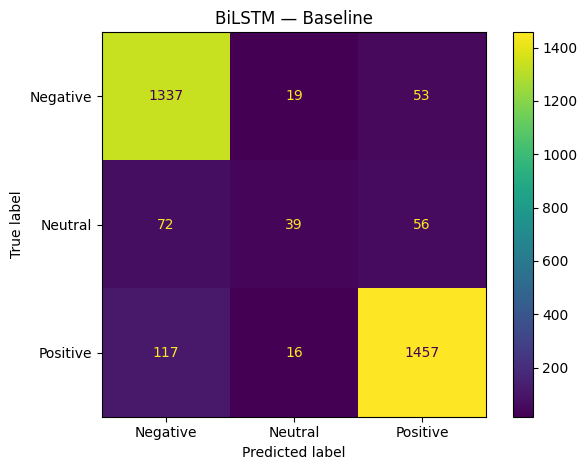

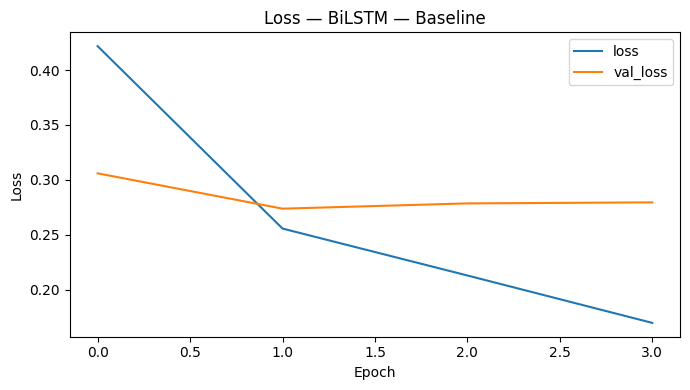

In [ ]:

tf.keras.backend.clear_session()

bilstm_baseline = build_bilstm_model()
bilstm_baseline.summary()

bilstm_baseline, history_bilstm_baseline = (
    train_and_evaluate_rnn(
        model=bilstm_baseline,
        model_name="BiLSTM",
        experiment="Baseline",
        class_weight=None
    )
)


In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history, title, file_name):
    epochs = range(1, len(history.history["loss"]) + 1)

    plt.figure(figsize=(10, 5))

    plt.plot(
        epochs,
        history.history["accuracy"],
        label="Train Accuracy"
    )
    plt.plot(
        epochs,
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.plot(
        epochs,
        history.history["loss"],
        label="Train Loss"
    )
    plt.plot(
        epochs,
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Giá trị")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        file_name,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

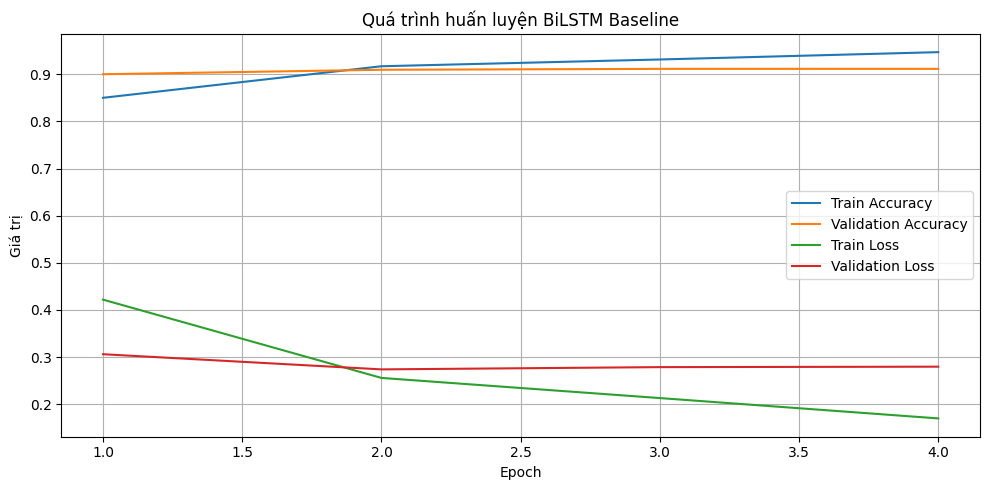

In [ ]:
plot_training_history(
    history_bilstm_baseline,
    "Quá trình huấn luyện BiLSTM Baseline",
    "anh_trainingBiLSTM_baseline.png"
)


## 3. BiLSTM sử dụng trọng số lớp


Epoch 1/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.7772 - loss: 0.6857 - val_accuracy: 0.8250 - val_loss: 0.4424 - learning_rate: 0.0010
Epoch 2/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8601 - loss: 0.4144 - val_accuracy: 0.8692 - val_loss: 0.3808 - learning_rate: 0.0010
Epoch 3/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8926 - loss: 0.3293 - val_accuracy: 0.8534 - val_loss: 0.3960 - learning_rate: 0.0010
Epoch 4/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9131 - loss: 0.2478 - val_accuracy: 0.8718 - val_loss: 0.3726 - learning_rate: 5.0000e-04
Epoch 5/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9228 - loss: 0.2104 - val_accuracy: 0.8819 - val_loss: 0.3693 - learning_rate: 5.0000e-04
Epoch 6/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9270 - loss: 0.1922 - val_accuracy: 0.8850 - val_loss: 0.3697 - learning_rate: 5.0000e-04
Epoch 7/8
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9400 - los

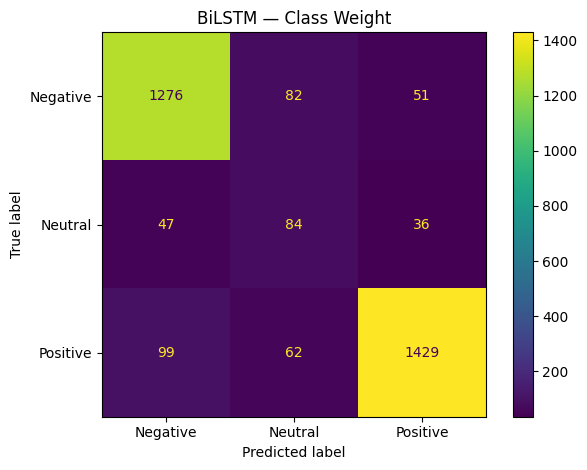

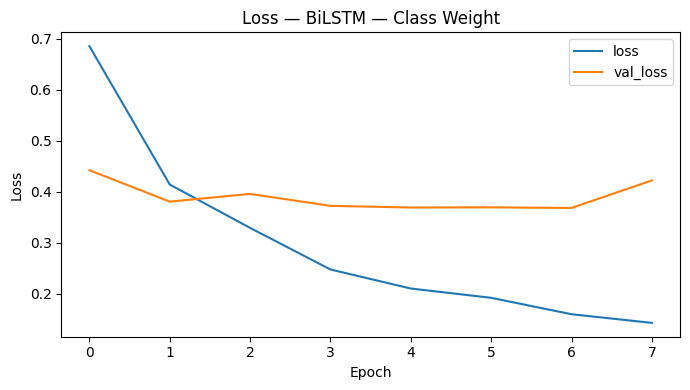

In [ ]:

tf.keras.backend.clear_session()

bilstm_balanced = build_bilstm_model()

bilstm_balanced, history_bilstm_balanced = (
    train_and_evaluate_rnn(
        model=bilstm_balanced,
        model_name="BiLSTM",
        experiment="Class Weight",
        class_weight=CLASS_WEIGHT
    )
)


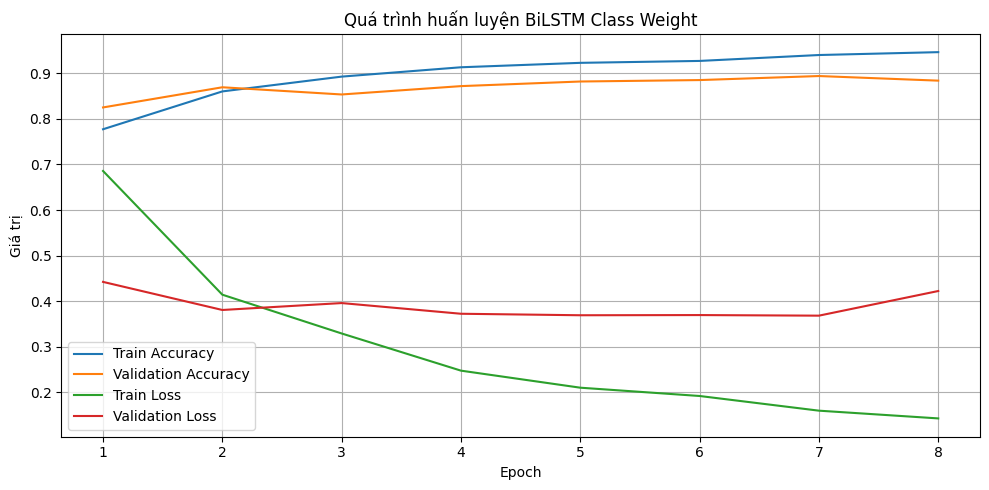

In [ ]:
plot_training_history(
    history_bilstm_balanced,
    "Quá trình huấn luyện BiLSTM Class Weight",
    "anh_trainingBiLSTM_classweight.png"
)

In [ ]:

bilstm_results = export_results(
    "bilstm_results.csv"
)


,Model,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Negative Precision,Negative Recall,Negative F1,Neutral Precision,Neutral Recall,Neutral F1,Positive Precision,Positive Recall,Positive F1,Neutral Support
0,BiLSTM,Baseline,0.8948,0.7779,0.6996,0.7193,0.8862,0.8761,0.9489,0.9111,0.5270,0.2335,0.3237,0.9304,0.9164,0.9233,167
1,BiLSTM,Class Weight,0.8809,0.7361,0.7691,0.7490,0.8857,0.8973,0.9056,0.9014,0.3684,0.5030,0.4253,0.9426,0.8987,0.9202,167


Đã lưu kết quả tại: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/bilstm_results.csv


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import os
import json

SEQUENCE_LENGTH = 80

token_input = keras.Input(
    shape=(SEQUENCE_LENGTH,),
    dtype=tf.int32,
    name="input_ids"
)

x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="embedding"
)(token_input)

# Dùng unroll=True để tránh CudnnRNNV3
x = layers.Bidirectional(
    layers.LSTM(
        RNN_UNITS,
        unroll=True
    ),
    name="bidirectional_lstm"
)(x)

x = layers.Dropout(
    0.4,
    name="dropout_1"
)(x)

x = layers.Dense(
    64,
    activation="relu",
    name="dense_hidden"
)(x)

x = layers.Dropout(
    0.3,
    name="dropout_2"
)(x)

output = layers.Dense(
    3,
    activation="softmax",
    name="sentiment"
)(x)

bilstm_export = keras.Model(
    inputs=token_input,
    outputs=output,
    name="bilstm_export"
)

bilstm_export.summary()

Model: "bilstm_export"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 80)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │    322,048 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 80)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_lstm  │ (None, 256)       │    263,168 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ bidirectional_ls… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_hidden        │ (None, 64)        │     16,448 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_hidden[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment (Dense)   │ (None, 3)         │        195 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 601,859 (2.30 MB)

 Trainable params: 601,859 (2.30 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Embedding
bilstm_export.get_layer(
    "embedding"
).set_weights(
    bilstm_balanced
    .get_layer("embedding")
    .get_weights()
)

# Bidirectional LSTM
bilstm_export.get_layer(
    "bidirectional_lstm"
).set_weights(
    bilstm_balanced
    .get_layer("bidirectional_lstm")
    .get_weights()
)

# Các Dense layer của model gốc
original_dense_layers = [
    layer
    for layer in bilstm_balanced.layers
    if isinstance(
        layer,
        keras.layers.Dense
    )
]

print(
    "Dense gốc:",
    [
        layer.name
        for layer in original_dense_layers
    ]
)

# Dense 64
bilstm_export.get_layer(
    "dense_hidden"
).set_weights(
    original_dense_layers[0]
    .get_weights()
)

# Dense output
bilstm_export.get_layer(
    "sentiment"
).set_weights(
    original_dense_layers[1]
    .get_weights()
)

print("Đã copy toàn bộ trọng số.")

Dense gốc: ['dense', 'sentiment']
Đã copy toàn bộ trọng số.


In [ ]:
test_text = "giảng viên nhiệt tình"

sequence = text_vectorizer(
    tf.constant([test_text])
)

# Model gốc
original_probs = (
    bilstm_balanced(
        tf.constant([test_text]),
        training=False
    )
    .numpy()[0]
)

# Model dành cho export
export_probs = (
    bilstm_export(
        tf.cast(
            sequence,
            tf.int32
        ),
        training=False
    )
    .numpy()[0]
)

print(
    "Model gốc:",
    original_probs
)

print(
    "Model export:",
    export_probs
)

print(
    "Sai lệch lớn nhất:",
    np.max(
        np.abs(
            original_probs
            - export_probs
        )
    )
)

print(
    "Nhãn model gốc:",
    ID2LABEL[
        int(
            np.argmax(
                original_probs
            )
        )
    ]
)

print(
    "Nhãn model export:",
    ID2LABEL[
        int(
            np.argmax(
                export_probs
            )
        )
    ]
)

Model gốc: [3.5139855e-03 8.3593396e-04 9.9565011e-01]
Model export: [3.5139902e-03 8.3593559e-04 9.9565011e-01]
Sai lệch lớn nhất: 4.656613e-09
Nhãn model gốc: Positive
Nhãn model export: Positive


In [ ]:
test_text = "giảng viên nhiệt tình"

sequence = text_vectorizer(
    tf.constant([test_text])
)

# Model gốc
original_probs = (
    bilstm_balanced(
        tf.constant([test_text]),
        training=False
    )
    .numpy()[0]
)

# Model dành cho export
export_probs = (
    bilstm_export(
        tf.cast(
            sequence,
            tf.int32
        ),
        training=False
    )
    .numpy()[0]
)

print(
    "Model gốc:",
    original_probs
)

print(
    "Model export:",
    export_probs
)

print(
    "Sai lệch lớn nhất:",
    np.max(
        np.abs(
            original_probs
            - export_probs
        )
    )
)

print(
    "Nhãn model gốc:",
    ID2LABEL[
        int(
            np.argmax(
                original_probs
            )
        )
    ]
)

print(
    "Nhãn model export:",
    ID2LABEL[
        int(
            np.argmax(
                export_probs
            )
        )
    ]
)

Model gốc: [3.5139855e-03 8.3593396e-04 9.9565011e-01]
Model export: [3.5139902e-03 8.3593559e-04 9.9565011e-01]
Sai lệch lớn nhất: 4.656613e-09
Nhãn model gốc: Positive
Nhãn model export: Positive


In [ ]:
SAVE_DIR = (
    "/content/drive/MyDrive/"
    "NC_MatCanBang_UIT_VSFC/"
    "SavedModels/"
    "bilstm_weighted"
)

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

vocabulary = (
    text_vectorizer
    .get_vocabulary()
)

VOCAB_PATH = os.path.join(
    SAVE_DIR,
    "vocabulary.json"
)

with open(
    VOCAB_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        vocabulary,
        f,
        ensure_ascii=False
    )

print(
    "Đã lưu:",
    VOCAB_PATH
)

print(
    "Số từ:",
    len(vocabulary)
)

Đã lưu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/bilstm_weighted/vocabulary.json
Số từ: 2516


In [ ]:
!pip install -q tf2onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 47.6 MB/s eta 0:00:00


In [ ]:
import tf2onnx

ONNX_PATH = os.path.join(
    SAVE_DIR,
    "bilstm_model.onnx"
)

if os.path.exists(ONNX_PATH):
    os.remove(ONNX_PATH)

input_signature = [
    tf.TensorSpec(
        shape=[
            None,
            SEQUENCE_LENGTH
        ],
        dtype=tf.int32,
        name="input_ids"
    )
]

model_proto, _ = (
    tf2onnx.convert.from_keras(
        bilstm_export,
        input_signature=
            input_signature,
        opset=17,
        output_path=ONNX_PATH
    )
)

print(
    "Đã tạo:",
    ONNX_PATH
)

print(
    "Dung lượng:",
    round(
        os.path.getsize(
            ONNX_PATH
        ) / (1024 ** 2),
        2
    ),
    "MB"
)

Đã tạo: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/bilstm_weighted/bilstm_model.onnx
Dung lượng: 3.44 MB


In [ ]:
import os
import tensorflow as tf
import tf2onnx

ONNX_PATH = os.path.join(
    SAVE_DIR,
    "bilstm_model.onnx"
)

if os.path.exists(ONNX_PATH):
    os.remove(ONNX_PATH)

input_signature = [
    tf.TensorSpec(
        shape=[None, SEQUENCE_LENGTH],
        dtype=tf.int32,
        name="input_ids"
    )
]

model_proto, _ = tf2onnx.convert.from_keras(
    bilstm_export,
    input_signature=input_signature,
    opset=17,
    output_path=ONNX_PATH
)

print("Đã tạo:", ONNX_PATH)

print(
    "Dung lượng:",
    round(
        os.path.getsize(ONNX_PATH)
        / (1024 ** 2),
        2
    ),
    "MB"
)

Đã tạo: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/bilstm_weighted/bilstm_model.onnx
Dung lượng: 3.44 MB


In [ ]:
import onnxruntime as ort
import numpy as np
import tensorflow as tf

session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CPUExecutionProvider"]
)

test_text = "giảng viên nhiệt tình"

sequence = text_vectorizer(
    tf.constant([test_text])
).numpy().astype(np.int32)


# =========================
# TensorFlow
# =========================

tf_probs = bilstm_export(
    sequence,
    training=False
).numpy()[0]


# =========================
# ONNX
# =========================

input_name = (
    session.get_inputs()[0].name
)

onnx_output = session.run(
    None,
    {
        input_name: sequence
    }
)

onnx_probs = np.asarray(
    onnx_output[0]
)[0]


# =========================
# So sánh
# =========================

print(
    "TensorFlow:",
    tf_probs
)

print(
    "ONNX:",
    onnx_probs
)

print(
    "Sai lệch lớn nhất:",
    np.max(
        np.abs(
            tf_probs
            - onnx_probs
        )
    )
)

print(
    "\nNhãn TensorFlow:",
    ID2LABEL[
        int(np.argmax(tf_probs))
    ]
)

print(
    "Nhãn ONNX:",
    ID2LABEL[
        int(np.argmax(onnx_probs))
    ]
)

TensorFlow: [3.5139902e-03 8.3593559e-04 9.9565011e-01]
ONNX: [3.5139923e-03 8.3593559e-04 9.9565011e-01]
Sai lệch lớn nhất: 2.0954758e-09

Nhãn TensorFlow: Positive
Nhãn ONNX: Positive


In [ ]:
from huggingface_hub import login

login()

In [ ]:
from huggingface_hub import (
    create_repo,
    upload_file
)

BILSTM_REPO_ID = (
    "hnhut/"
    "uit-vsfc-bilstm-weighted"
)

create_repo(
    repo_id=BILSTM_REPO_ID,
    repo_type="model",
    private=False,
    exist_ok=True
)

upload_file(
    path_or_fileobj=ONNX_PATH,
    path_in_repo="bilstm_model.onnx",
    repo_id=BILSTM_REPO_ID,
    repo_type="model",
    commit_message=(
        "Upload BiLSTM "
        "Class Weight ONNX model"
    )
)

upload_file(
    path_or_fileobj=VOCAB_PATH,
    path_in_repo="vocabulary.json",
    repo_id=BILSTM_REPO_ID,
    repo_type="model",
    commit_message=(
        "Upload BiLSTM vocabulary"
    )
)

print(
    "Đã upload:",
    BILSTM_REPO_ID
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...eighted/bilstm_model.onnx:  21%|##1       |  772kB / 3.61MB            

Đã upload: hnhut/uit-vsfc-bilstm-weighted
